# 03 · Results analysis

All numbers come from the fixed test set (200 images per class), produced by `scripts/run_training.py` and `scripts/run_evaluation.py`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import config, data_loader, preprocess
from src.utils import setup_matplotlib
plt = setup_matplotlib()
%matplotlib inline
MET, FIG = config.PATHS.metrics, config.PATHS.figures
def show(name):
    from IPython.display import Image, display
    p = FIG / name
    display(Image(filename=str(p))) if p.exists() else print(f"{name} not generated yet")

## Model comparison (500 training images per class)

In [2]:
mc = json.loads((MET / 'model_comparison.json').read_text())
pd.DataFrame(mc['models']).T[['accuracy', 'macro_f1', 'macro_precision', 'macro_recall']].round(4)

,accuracy,macro_f1,macro_precision,macro_recall
rf,0.745702,0.742933,0.744887,0.745702
svm,0.845,0.845116,0.846664,0.845
xgb,0.782193,0.783421,0.786367,0.782193
stack,0.813333,0.812832,0.813298,0.813333


In [3]:
pd.DataFrame({m: v['per_category_accuracy'] for m, v in mc['models'].items()}).T.round(4)

,consonant,digit,vowel
rf,0.6997,0.8205,0.8175
svm,0.8101,0.9120,0.8908
xgb,0.7457,0.8530,0.8296
stack,0.7797,0.8830,0.8533


In [4]:
p = MET / 'cross_validation.json'
print(json.loads(p.read_text())['summary'] if p.exists() else 'CV not run yet')

CV not run yet


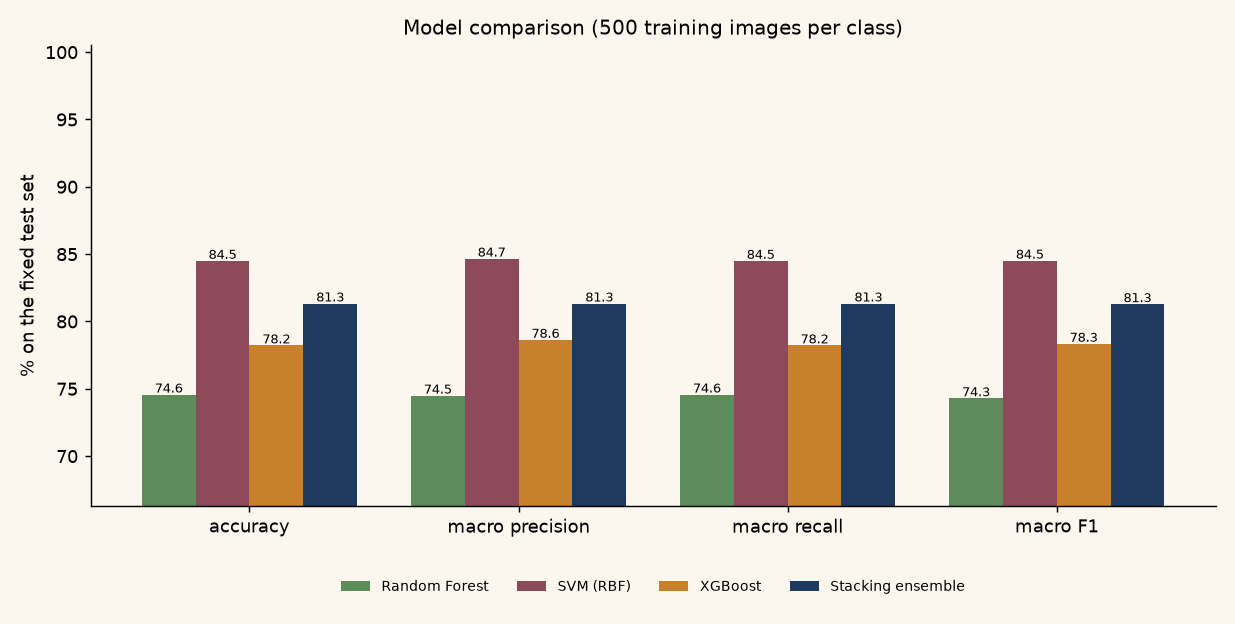

In [5]:
show('model_comparison.png')

## Research question: learning curve, classical vs untuned CNN

In [6]:
cl = MET / 'learning_curve_classical.json'; cn = MET / 'learning_curve_cnn.json'
for p in (cl, cn):
    if p.exists():
        d = json.loads(p.read_text())
        print(d['label']); print(pd.DataFrame([{'n/class': q['train_per_class'], 'accuracy': q['accuracy'], 'train s': q.get('train_time_s')} for q in d['points']]).to_string(index=False))

Classical: fused features + stacking
 n/class  accuracy  train s
      72  0.698246   232.68
     500  0.813333  6034.80


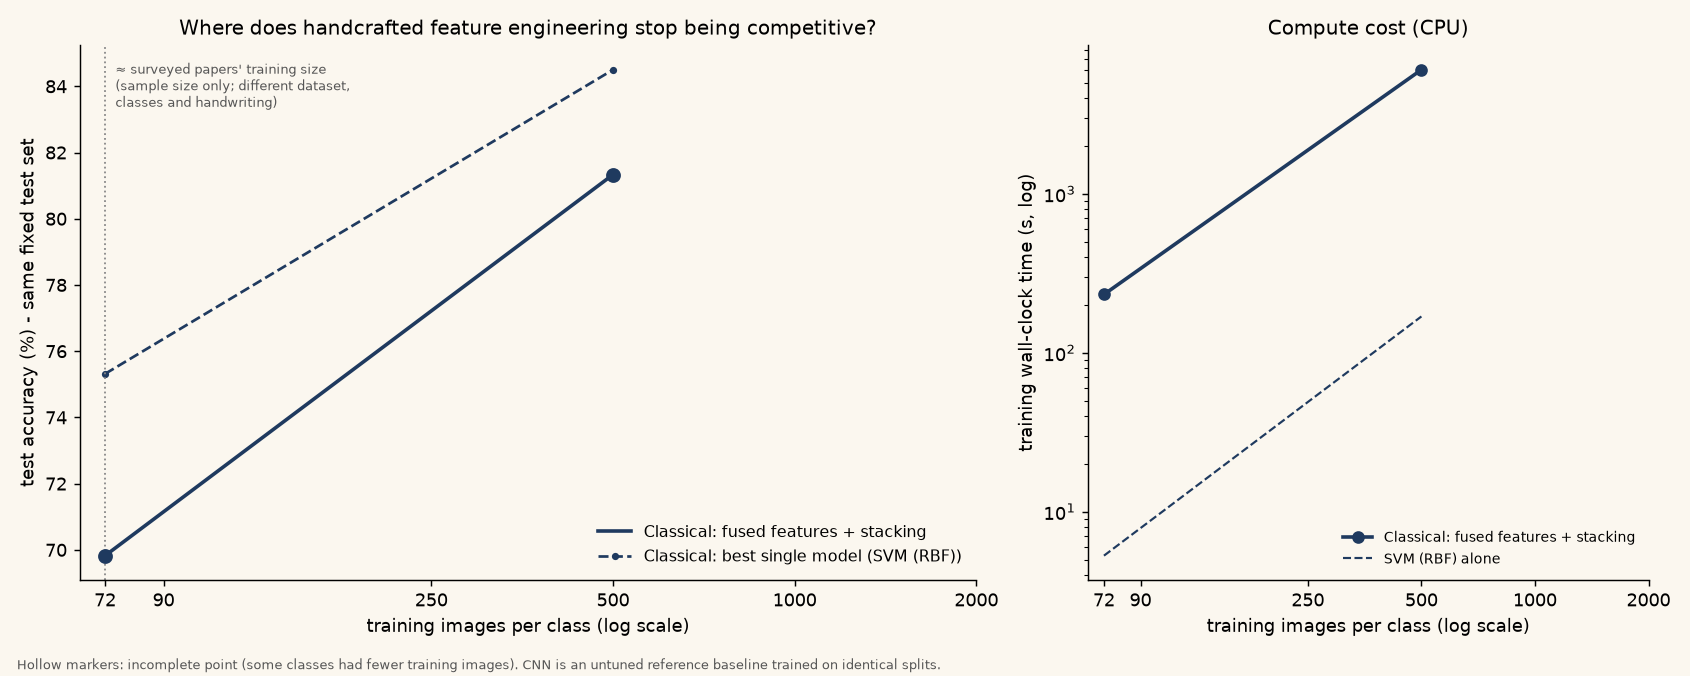

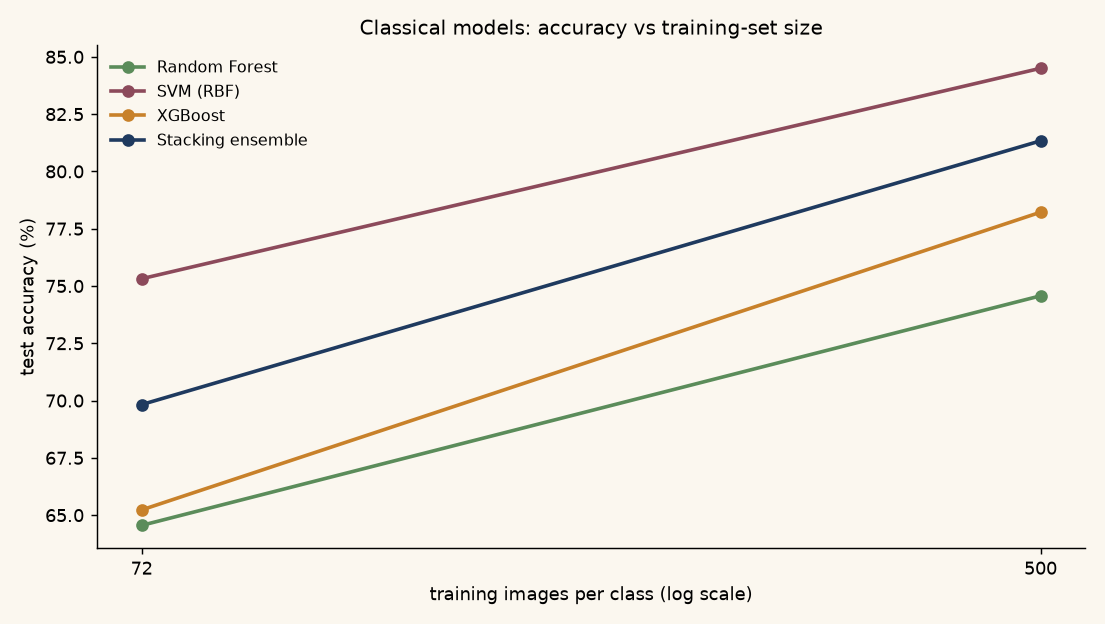

In [7]:
show('learning_curve_classical_vs_cnn.png'); show('learning_curve_classical_models.png')

## Ablation: does fusion help?

In [8]:
p = MET / 'ablation.json'
if p.exists():
    ab = json.loads(p.read_text())['feature_sets']
    display(pd.DataFrame({k: {m: v['models'][m]['accuracy'] for m in v['models']} for k, v in ab.items()}).T.round(4))
show('ablation.png')

ablation.png not generated yet


## PCA vs LDA

In [9]:
p = MET / 'reduction_comparison.json'
if p.exists():
    r = json.loads(p.read_text())['methods']
    display(pd.DataFrame({k: {m: v['models'][m]['accuracy'] for m in v['models']} | {'dims': v['n_components']} for k, v in r.items()}).T)

## Errors: per-class F1 and the most confused pairs

In [10]:
pd.read_csv(MET / 'per_class_metrics.csv').head(10)

,label,category,precision,recall,f1,support
0,thha,consonant,0.484375,0.465,0.474490,200
1,h,consonant,0.519608,0.530,0.524752,200
2,p,consonant,0.571429,0.560,0.565657,200
3,th,consonant,0.666667,0.650,0.658228,200
4,b,consonant,0.685567,0.665,0.675127,200
5,i,vowel,0.660465,0.710,0.684337,200
6,dha,consonant,0.718919,0.665,0.690909,200
7,tha,consonant,0.710526,0.675,0.692308,200
8,ph,consonant,0.772727,0.680,0.723404,200
9,ii,vowel,0.727273,0.720,0.723618,200


In [11]:
pd.read_csv(MET / 'most_confused_pairs.csv').head(15)

,class_a,class_b,a_as_b,b_as_a,total_confusions,a_as_b_rate,b_as_a_rate,pair_error_rate
0,i,ii,42,49,91,0.210,0.245,0.2275
1,h,thha,40,38,78,0.200,0.190,0.1950
2,five,six,24,29,53,0.120,0.145,0.1325
3,ja,n,26,27,53,0.130,0.135,0.1325
4,p,thha,24,29,53,0.120,0.145,0.1325
5,bh,ph,19,24,43,0.095,0.120,0.1075
6,k,m,27,15,42,0.135,0.075,0.1050
7,h,p,18,21,39,0.090,0.105,0.0975
8,r,th,17,19,36,0.085,0.095,0.0900
9,d,th,21,13,34,0.105,0.065,0.0850


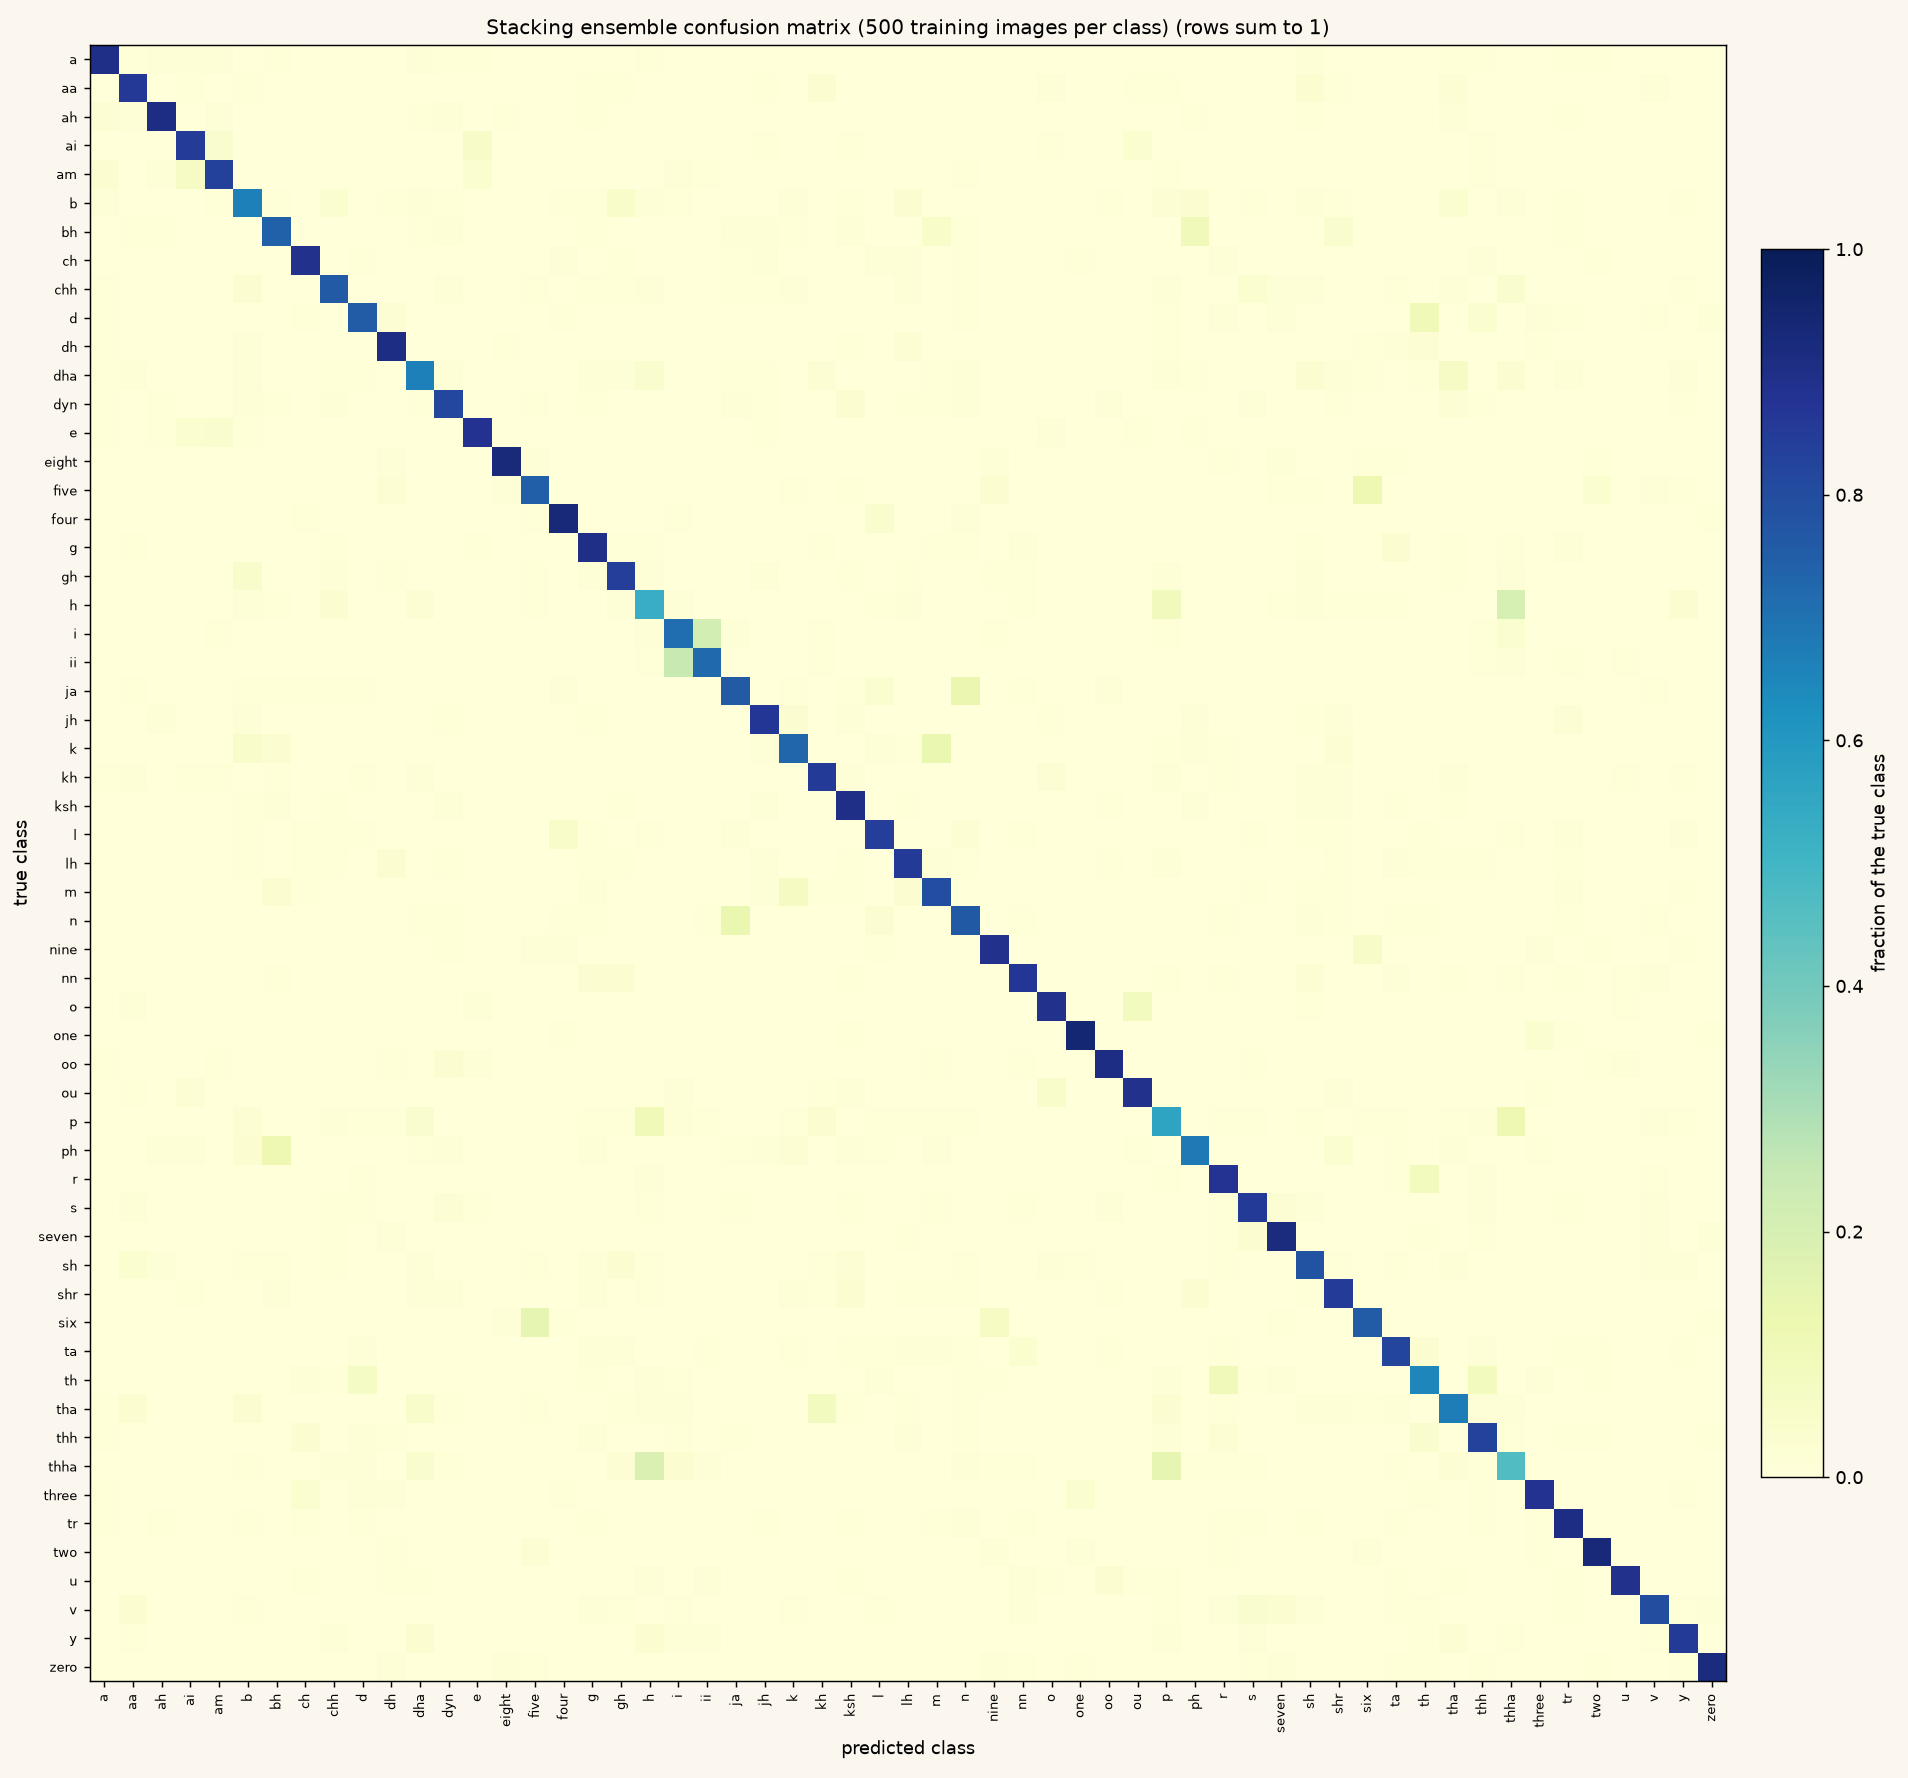

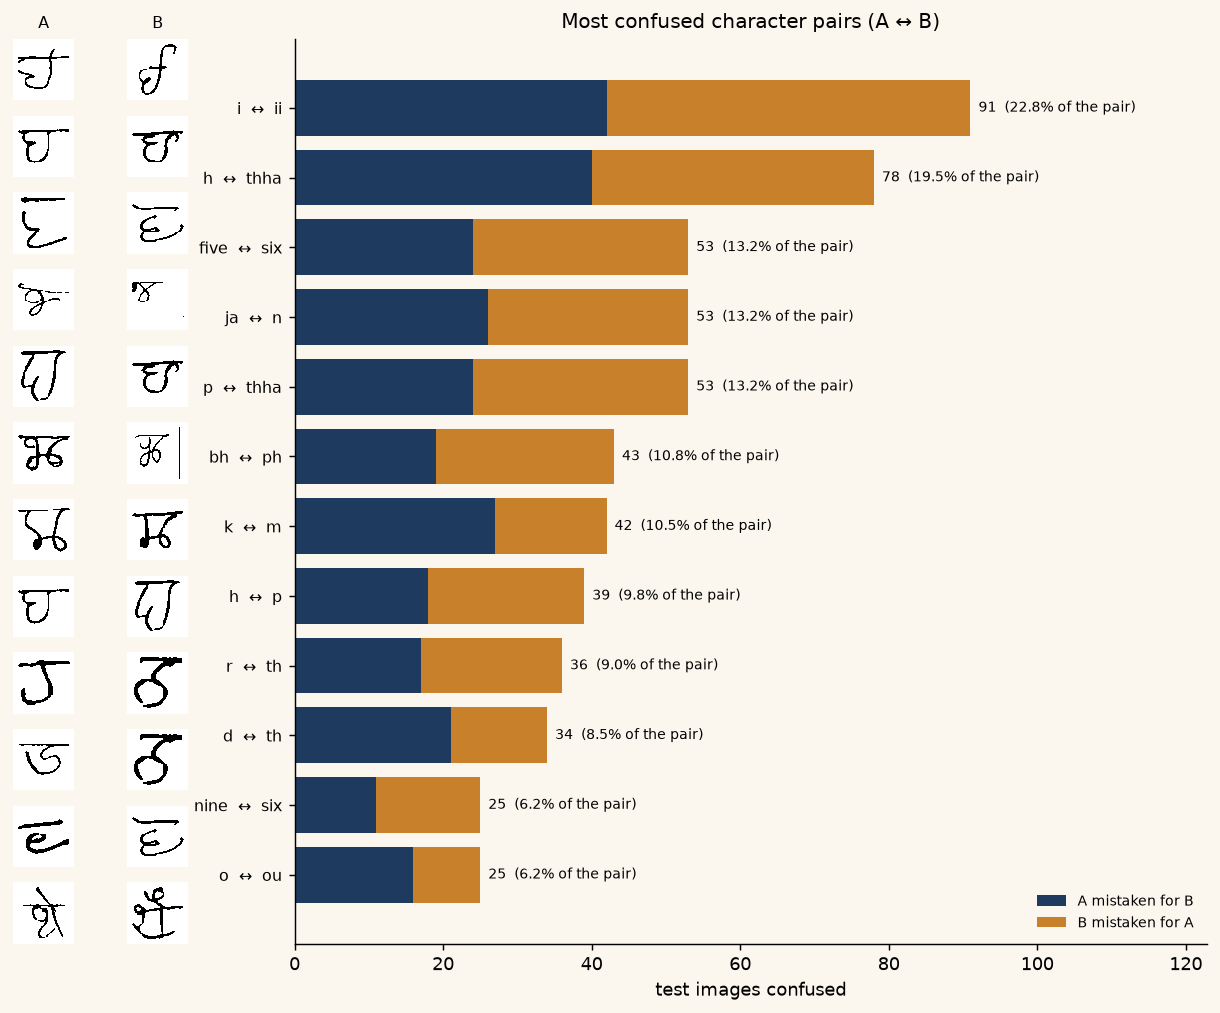

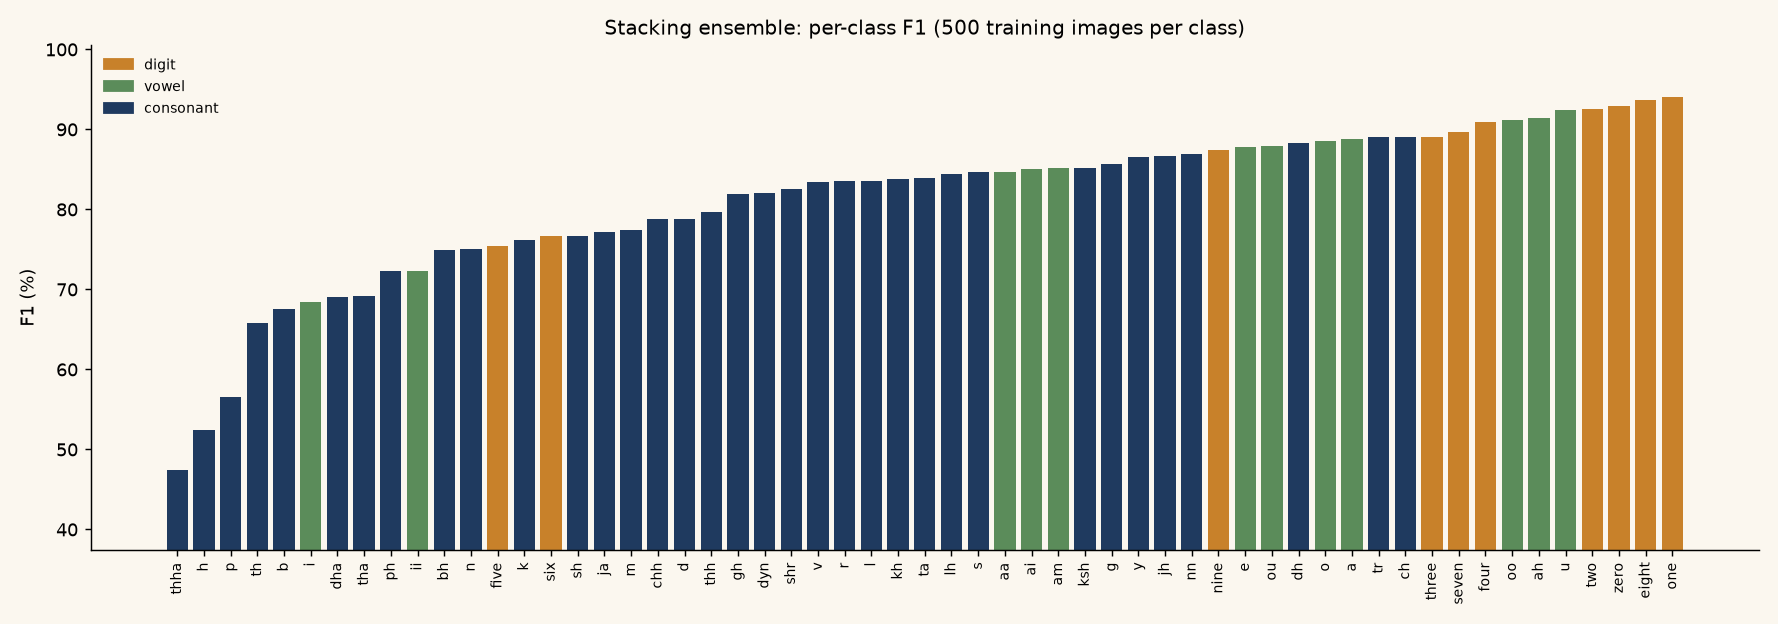

In [12]:
show('confusion_matrix.png'); show('most_confused_pairs.png'); show('per_class_f1.png')

## Explainability

family share: {'hog': 0.436, 'zernike': 0.17, 'lbp': 0.394}
faithfulness: {'groups_removed': 3, 'mean_probability_drop_top_shap': 0.44728336269459856, 'mean_probability_drop_random': 0.08385664380747876}
max additivity error: 8.770259052326423e-08


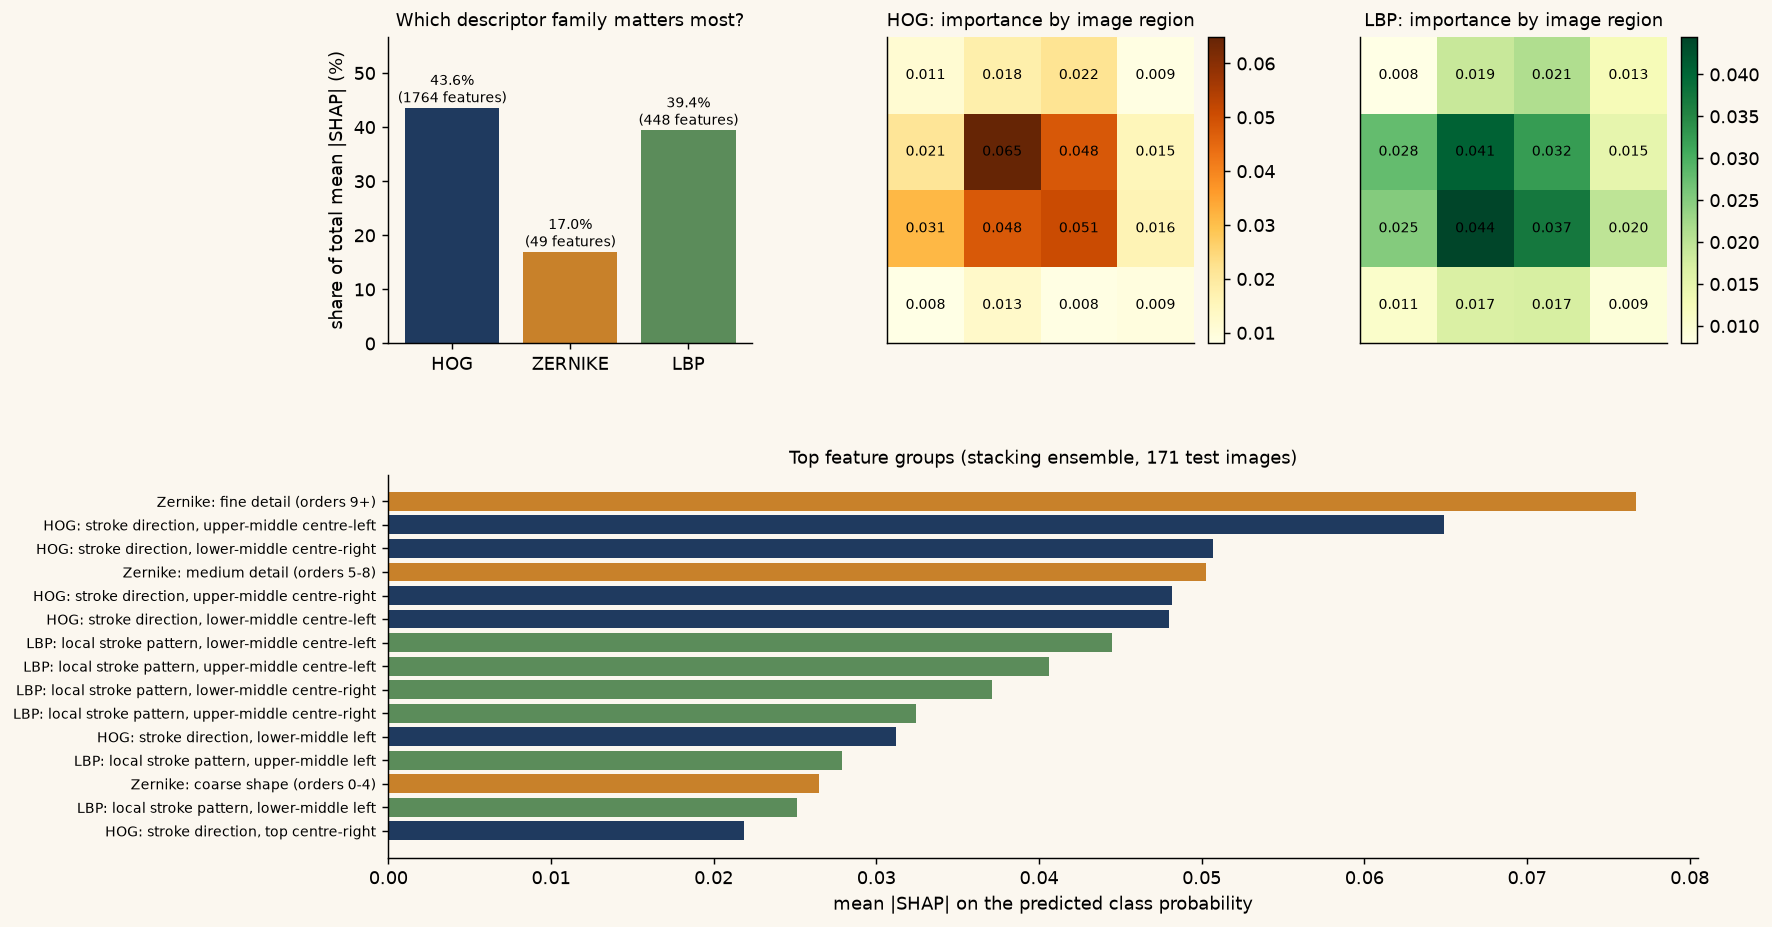

In [13]:
p = config.PATHS.shap / 'global_importance.json'
if p.exists():
    g = json.loads(p.read_text())
    print('family share:', {k: round(v, 3) for k, v in g['family_share'].items()})
    print('faithfulness:', g['faithfulness_deletion_test'])
    print('max additivity error:', g['max_additivity_error'])
show('shap_global_importance.png')